Universidad del Valle de Guatemala  
Departamento de Ciencias de la Computación  
CC3084 - Data Science - sección 40

Integrantes:  
- Cristian Túnchez (231359)
- Dulce Ambrosio (231143)
- Daniel Chet (231177)
- Javier Linares (231135)

# 05. Comparación de resultados y figuras del informe

**MAP - Charting Student Math Misunderstandings**

En este cuaderno se reúnen las métricas de todos los modelos y se producen las visualizaciones estáticas que acompañan al informe. Las figuras se guardan en `reports/figures/`.

Requiere haber ejecutado antes el cuaderno 03. El cuaderno 04 es opcional: si sus resultados están disponibles, el transformer se incorpora a la comparación.

## 0. Arranque

Este cuaderno funciona igual en **Google Colab** y en una instalación local.

En Colab la celda siguiente clona el repositorio e instala las dependencias. Como las métricas
las produce el cuaderno 03, hay que subir `artefactos_modelado.zip` cuando se solicite.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
REPOSITORIO = "https://github.com/Tunchxz/math-misconception-map.git"
CARPETA = "math-misconception-map"

if EN_COLAB:
    if not Path(CARPETA).exists():
        subprocess.run(["git", "clone", "--depth", "1", "-q", REPOSITORIO, CARPETA], check=True)
    os.chdir(f"/content/{CARPETA}")
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True
    )

RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

print("Entorno:", "Google Colab" if EN_COLAB else "local")
print("Raíz del proyecto:", RAIZ)

Entorno: local
Raíz del proyecto: /home/sebas/github/Data-Science/math-misconception-map


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import DATA_TRANSFORMED, FIGURES, PALETA_CUALITATIVA
from src.data.make_dataset import asegurar_datos, cargar_transformado
from src.visualization.visualize import guardar_figura, set_estilo

set_estilo()
pd.set_option("display.width", 170)
FIGURES.mkdir(parents=True, exist_ok=True)

if EN_COLAB and not (DATA_TRANSFORMED / "metricas_clasicos.parquet").exists():
    from google.colab import files

    print("Suba artefactos_modelado.zip, generado por el cuaderno 03")
    subidos = files.upload()
    import zipfile

    with zipfile.ZipFile(next(iter(subidos))) as z:
        z.extractall("artefactos")
    import shutil

    shutil.copytree("artefactos/transformed", DATA_TRANSFORMED, dirs_exist_ok=True)
    shutil.copytree("artefactos/models", RAIZ / "models", dirs_exist_ok=True)

metricas = cargar_transformado("metricas_clasicos")
comparacion = cargar_transformado("comparacion_texto_contexto")
train = asegurar_datos(verbose=False)

print("Filas de métricas:", len(metricas))
print("Modelos:", metricas["modelo"].nunique(), "| Etapas:", metricas["etapa"].nunique())

Filas de métricas: 36
Modelos: 6 | Etapas: 3


## 1. Colores del informe

Se usa la paleta de Okabe-Ito, construida para ser distinguible bajo los tres tipos de
daltonismo. Los dos esquemas de validación reciben un color fijo en todas las figuras, de modo
que su significado no cambie de un gráfico a otro.

In [3]:
COLOR_ALEATORIO = "#56B4E9"
COLOR_AGRUPADO = "#D55E00"
COLOR_TEXTO = "#009E73"
COLOR_CONTEXTO = "#53606B"

COLOR_ESQUEMA = {"aleatorio": COLOR_ALEATORIO, "agrupado": COLOR_AGRUPADO}
ETIQUETA_ESQUEMA = {
    "aleatorio": "Aleatorio\n(preguntas ya vistas)",
    "agrupado": "Agrupado por pregunta\n(preguntas nuevas)",
}

orden_modelos = (
    metricas[metricas["etapa"] == "1. Category"]
    .groupby("modelo")["map@3"].max().sort_values().index.tolist()
)
print("Modelos ordenados por MAP@3:", orden_modelos)

Modelos ordenados por MAP@3: ['Linea base (mayoritaria)', 'Complement NB', 'Linea base por contexto', 'Gradient boosting', 'Regresion logistica', 'LinearSVC']


## 2. Figura 1: comparación de los modelos en las tres etapas

/home/sebas/github/Data-Science/math-misconception-map/reports/figures/fig1_comparacion_modelos.png


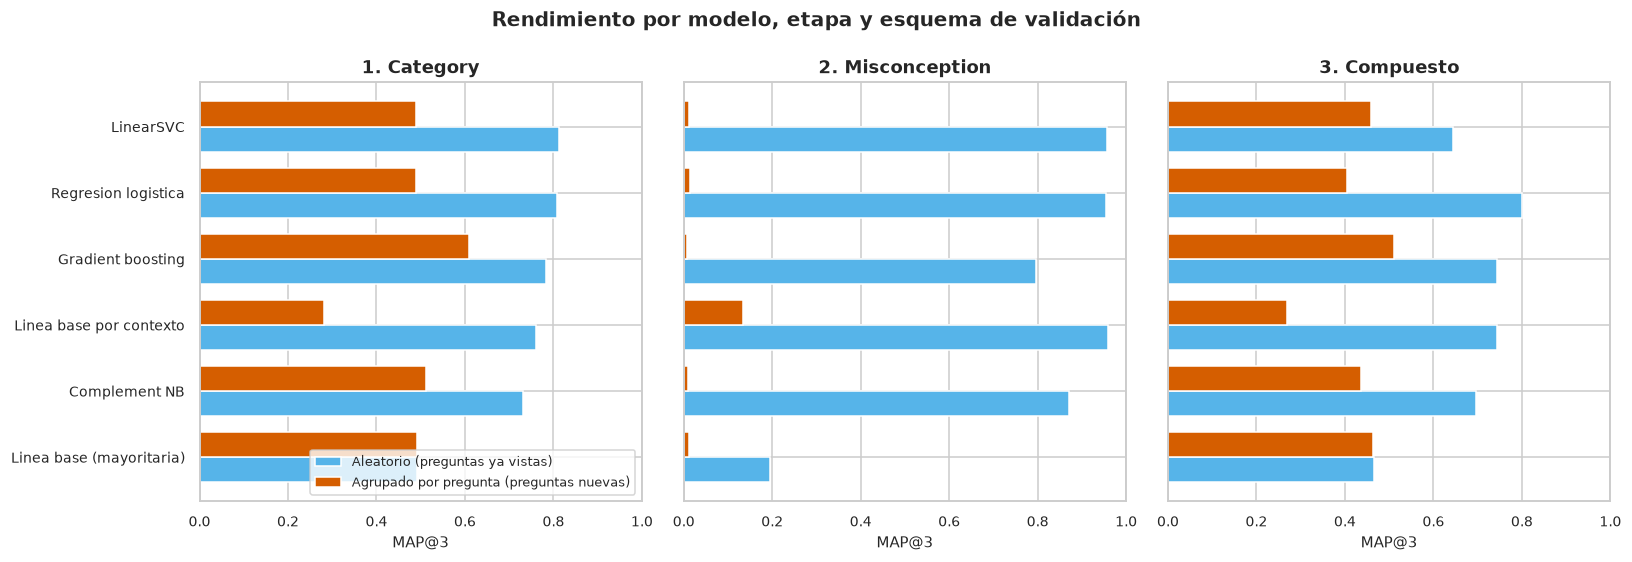

In [4]:
etapas = sorted(metricas["etapa"].unique())
fig, axes = plt.subplots(1, len(etapas), figsize=(15, 5.2), sharey=True)

for ax, etapa in zip(np.atleast_1d(axes), etapas):
    sub = metricas[metricas["etapa"] == etapa]
    pos = np.arange(len(orden_modelos))
    ancho = 0.38
    for i, esquema in enumerate(["aleatorio", "agrupado"]):
        valores = [
            sub[(sub["modelo"] == m) & (sub["esquema"] == esquema)]["map@3"].mean()
            for m in orden_modelos
        ]
        ax.barh(pos + (i - 0.5) * ancho, valores, height=ancho,
                color=COLOR_ESQUEMA[esquema], label=ETIQUETA_ESQUEMA[esquema].replace("\n", " "))
    ax.set_yticks(pos)
    ax.set_yticklabels(orden_modelos)
    ax.set_xlabel("MAP@3")
    ax.set_title(etapa)
    ax.set_xlim(0, 1)

axes[0].legend(loc="lower right", fontsize=8.5)
fig.suptitle("Rendimiento por modelo, etapa y esquema de validación",
             fontsize=13, fontweight="bold")
fig.tight_layout()
print(guardar_figura(fig, "fig1_comparacion_modelos"))
plt.show()

## 3. Figura 2: cuánta memorización de la pregunta hay

La diferencia entre validar con preguntas ya vistas y con preguntas nuevas mide directamente
cuánto del rendimiento proviene de reconocer la pregunta en lugar de entender la explicación.

/home/sebas/github/Data-Science/math-misconception-map/reports/figures/fig2_brecha_validacion.png


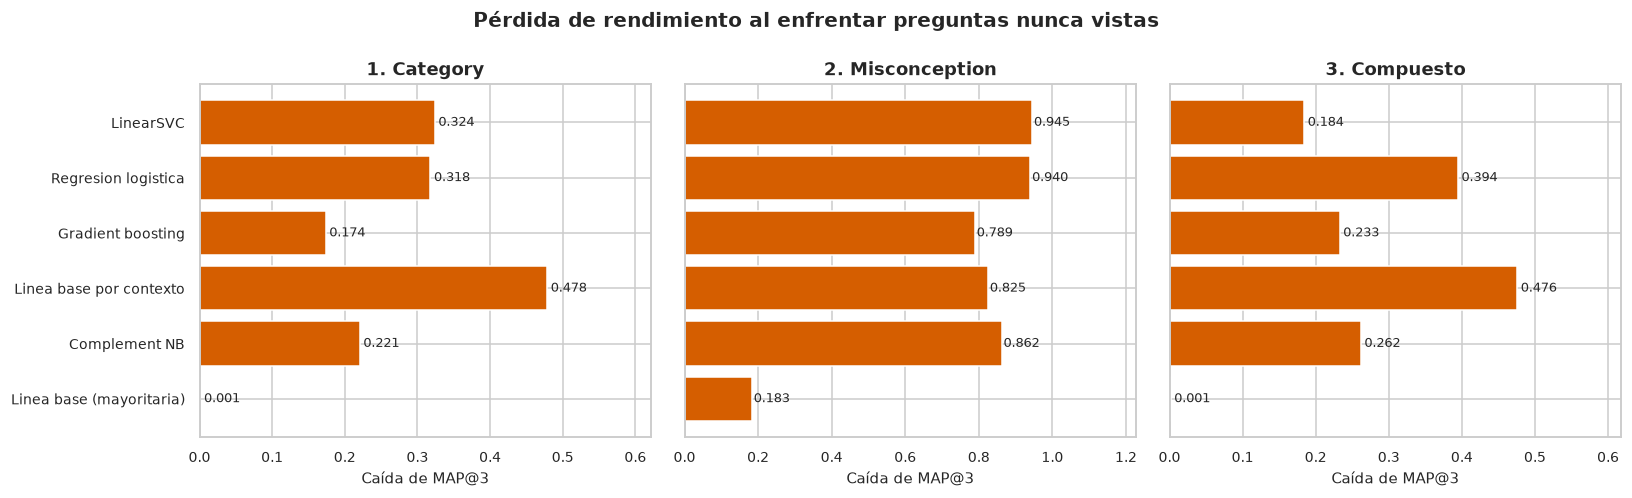

In [5]:
fig, axes = plt.subplots(1, len(etapas), figsize=(15, 4.6), sharey=True)

for ax, etapa in zip(np.atleast_1d(axes), etapas):
    p = (
        metricas[metricas["etapa"] == etapa]
        .pivot_table(index="modelo", columns="esquema", values="map@3")
        .reindex(orden_modelos)
    )
    brecha = (p["aleatorio"] - p["agrupado"]).fillna(0)
    colores = [COLOR_AGRUPADO if v > 0.1 else COLOR_ALEATORIO for v in brecha]
    ax.barh(brecha.index, brecha.values, color=colores)
    for y, v in enumerate(brecha.values):
        ax.text(v + 0.005, y, f"{v:.3f}", va="center", fontsize=8.5)
    ax.set_xlabel("Caída de MAP@3")
    ax.set_title(etapa)
    ax.set_xlim(0, max(0.05, brecha.max() * 1.3))

fig.suptitle("Pérdida de rendimiento al enfrentar preguntas nunca vistas",
             fontsize=13, fontweight="bold")
fig.tight_layout()
print(guardar_figura(fig, "fig2_brecha_validacion"))
plt.show()

## 4. Figura 3: cuánto aporta leer la explicación

Se contrasta el mejor modelo que lee el texto contra la línea base que solo conoce la pregunta y
la opción marcada.

/home/sebas/github/Data-Science/math-misconception-map/reports/figures/fig3_aporte_del_texto.png


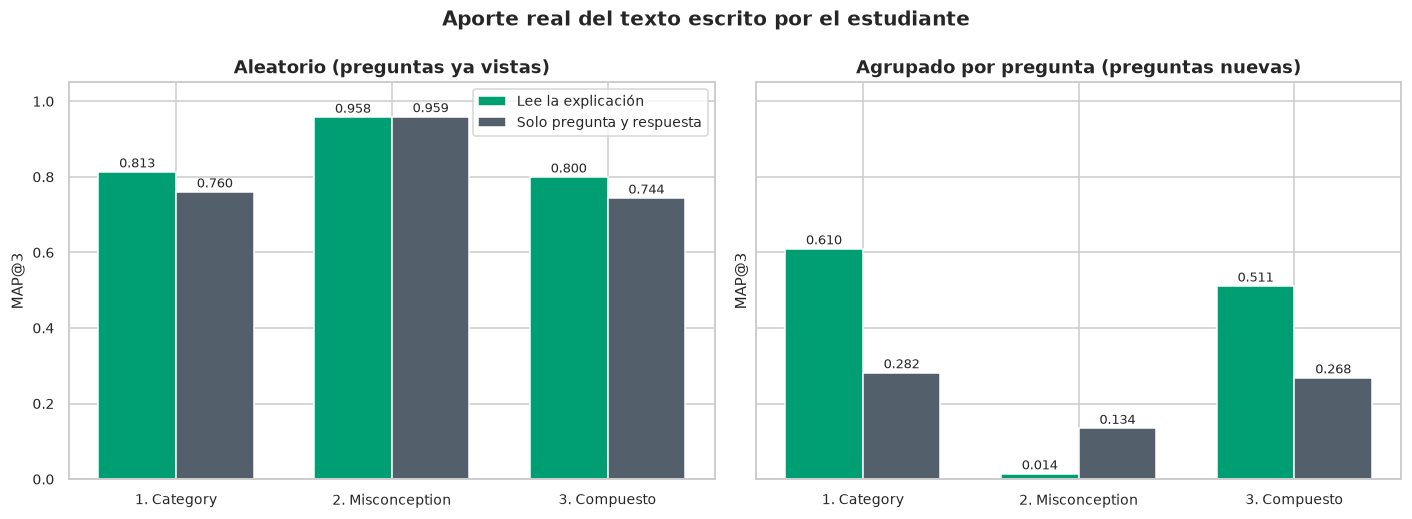

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)

for ax, esquema in zip(axes, ["aleatorio", "agrupado"]):
    sub = comparacion[comparacion["esquema"] == esquema].sort_values("etapa")
    pos = np.arange(len(sub))
    ancho = 0.36
    ax.bar(pos - ancho / 2, sub["map3_con_texto"], ancho,
           color=COLOR_TEXTO, label="Lee la explicación")
    ax.bar(pos + ancho / 2, sub["map3_solo_contexto"], ancho,
           color=COLOR_CONTEXTO, label="Solo pregunta y respuesta")
    for x, (a, b) in enumerate(zip(sub["map3_con_texto"], sub["map3_solo_contexto"])):
        ax.text(x - ancho / 2, a + 0.012, f"{a:.3f}", ha="center", fontsize=8.5)
        ax.text(x + ancho / 2, b + 0.012, f"{b:.3f}", ha="center", fontsize=8.5)
    ax.set_xticks(pos)
    ax.set_xticklabels(sub["etapa"], fontsize=9)
    ax.set_ylabel("MAP@3")
    ax.set_title(ETIQUETA_ESQUEMA[esquema].replace("\n", " "))
    ax.set_ylim(0, 1.05)

axes[0].legend(loc="upper right", fontsize=9)
fig.suptitle("Aporte real del texto escrito por el estudiante", fontsize=13, fontweight="bold")
fig.tight_layout()
print(guardar_figura(fig, "fig3_aporte_del_texto"))
plt.show()

In [7]:
comparacion

,etapa,esquema,mejor_con_texto,map3_con_texto,map3_solo_contexto,ganancia
0,1. Category,aleatorio,LinearSVC,0.8131,0.7601,0.0530
1,1. Category,agrupado,Gradient boosting,0.6096,0.2816,0.3280
2,2. Misconception,aleatorio,LinearSVC,0.9577,0.9593,-0.0017
3,2. Misconception,agrupado,Regresion logistica,0.0140,0.1344,-0.1203
4,3. Compuesto,aleatorio,Regresion logistica,0.7996,0.7437,0.0559
5,3. Compuesto,agrupado,Gradient boosting,0.5109,0.2681,0.2428


## 5. Figura 4: rendimiento frente a costo de cómputo

/home/sebas/github/Data-Science/math-misconception-map/reports/figures/fig4_rendimiento_vs_costo.png


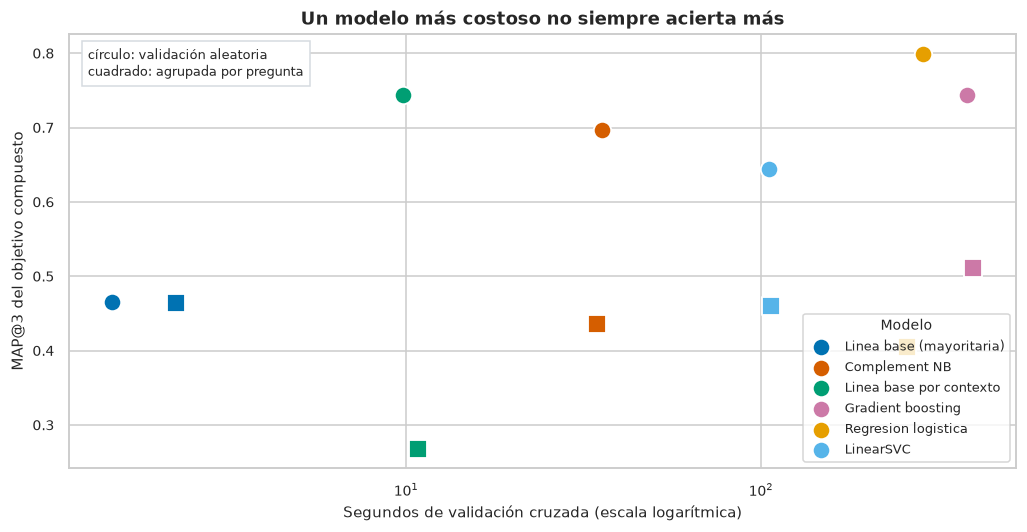

In [8]:
fig, ax = plt.subplots(figsize=(9.5, 5))

sub = metricas[(metricas["etapa"] == "3. Compuesto")]
for i, modelo in enumerate(orden_modelos):
    d = sub[sub["modelo"] == modelo]
    for esquema, marcador in [("aleatorio", "o"), ("agrupado", "s")]:
        fila = d[d["esquema"] == esquema]
        if fila.empty:
            continue
        ax.scatter(fila["segundos"], fila["map@3"], s=130, marker=marcador,
                   color=PALETA_CUALITATIVA[i % len(PALETA_CUALITATIVA)],
                   edgecolor="white", linewidth=1.2, zorder=3,
                   label=modelo if esquema == "aleatorio" else None)

ax.set_xscale("log")
ax.set_xlabel("Segundos de validación cruzada (escala logarítmica)")
ax.set_ylabel("MAP@3 del objetivo compuesto")
ax.set_title("Un modelo más costoso no siempre acierta más")
ax.legend(fontsize=8.5, loc="lower right", title="Modelo", title_fontsize=9)
ax.text(0.02, 0.97, "círculo: validación aleatoria\ncuadrado: agrupada por pregunta",
        transform=ax.transAxes, va="top", fontsize=8.5,
        bbox={"facecolor": "white", "edgecolor": "#D6DBE0"})
fig.tight_layout()
print(guardar_figura(fig, "fig4_rendimiento_vs_costo"))
plt.show()

## 6. Figura 5: el efecto del desbalance

Se relaciona la frecuencia de cada error conceptual con el número de preguntas en que aparece.
Esto conecta el desbalance observado en el análisis exploratorio con la dificultad que muestran
los modelos en la etapa 2.

/home/sebas/github/Data-Science/math-misconception-map/reports/figures/fig5_desbalance_y_cobertura.png


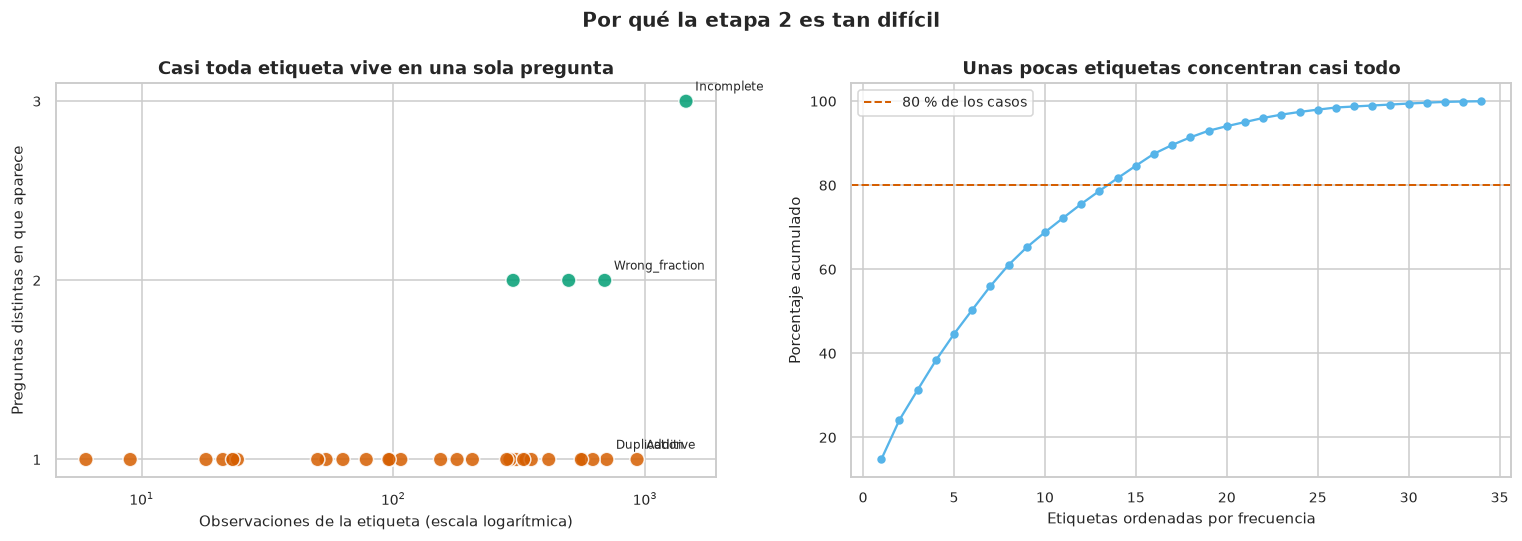


Etiquetas presentes en una sola pregunta: 30 de 34


In [9]:
con_error = train[train["misconception"] != "NA"].copy()
con_error["etiqueta"] = con_error["misconception"].replace({"Wrong_Fraction": "Wrong_fraction"})

perfil = (
    con_error.groupby("etiqueta")
    .agg(frecuencia=("row_id", "size"), preguntas=("QuestionId", "nunique"))
    .reset_index()
)

fig, (izq, der) = plt.subplots(1, 2, figsize=(14, 5))

colores = [COLOR_AGRUPADO if p == 1 else COLOR_TEXTO for p in perfil["preguntas"]]
izq.scatter(perfil["frecuencia"], perfil["preguntas"], s=90, c=colores,
            alpha=0.85, edgecolor="white", linewidth=1)
izq.set_xscale("log")
izq.set_yticks(sorted(perfil["preguntas"].unique()))
izq.set_xlabel("Observaciones de la etiqueta (escala logarítmica)")
izq.set_ylabel("Preguntas distintas en que aparece")
izq.set_title("Casi toda etiqueta vive en una sola pregunta")
for _, f in perfil.nlargest(4, "frecuencia").iterrows():
    izq.annotate(f["etiqueta"], (f["frecuencia"], f["preguntas"]),
                 textcoords="offset points", xytext=(6, 7), fontsize=8)

acumulado = (
    perfil.sort_values("frecuencia", ascending=False)["frecuencia"].cumsum()
    / perfil["frecuencia"].sum() * 100
)
der.plot(range(1, len(acumulado) + 1), acumulado.values, marker="o", ms=4.5,
         color=COLOR_ALEATORIO)
der.axhline(80, color=COLOR_AGRUPADO, ls="--", lw=1.3, label="80 % de los casos")
der.set_xlabel("Etiquetas ordenadas por frecuencia")
der.set_ylabel("Porcentaje acumulado")
der.set_title("Unas pocas etiquetas concentran casi todo")
der.legend(fontsize=9)

fig.suptitle("Por qué la etapa 2 es tan difícil", fontsize=13, fontweight="bold")
fig.tight_layout()
print(guardar_figura(fig, "fig5_desbalance_y_cobertura"))
plt.show()

print(f"\nEtiquetas presentes en una sola pregunta: "
      f"{(perfil['preguntas'] == 1).sum()} de {len(perfil)}")

## 7. El transformer frente a los modelos clásicos

El cuaderno 04 afinó un MiniLM destilado sobre la etapa 1. Para que la comparación sea justa
hay que resolver una diferencia de método: el transformer se evaluó sobre **una sola
partición**, la primera de la validación agrupada, mientras que los modelos clásicos se
promediaron sobre cinco.

Comparar un promedio de cinco particiones contra el resultado de una sola sería engañoso. Por
eso se vuelven a medir los modelos clásicos sobre exactamente la misma partición que usó el
transformer.

In [10]:
import joblib

from sklearn.model_selection import GroupKFold

ruta_minilm = RAIZ / "models" / "modelo_minilm" / "metricas.csv"

# En Colab el modelo del transformer no llega con los artefactos del cuaderno 03,
# porque se produce después. Se ofrece subirlo aquí.
if EN_COLAB and not ruta_minilm.exists():
    from google.colab import files
    import zipfile

    print("Opcional: suba modelo_minilm.zip, descargado del cuaderno 04.")
    print("Si lo omite, se genera el informe sin la comparación del transformer.")
    try:
        subidos = files.upload()
        if subidos:
            with zipfile.ZipFile(next(iter(subidos))) as z:
                z.extractall(RAIZ / "models" / "modelo_minilm")
    except Exception as e:
        print("No se subió el modelo:", e)

hay_transformer = ruta_minilm.exists()

if hay_transformer:
    minilm = pd.read_csv(ruta_minilm)
    print(minilm.round(4).to_string(index=False))
else:
    print("No se encontró models/modelo_minilm/metricas.csv")
    print("Ejecute el cuaderno 04 y descomprima el resultado en models/modelo_minilm/")

     experimento  f1_macro  f1_ponderado  segundos  minutos
solo_explicacion    0.3050        0.5581  193.7647      3.2
    con_contexto    0.2691        0.4796  144.0550      2.4


In [11]:
from src.features import build_features as bf
from src.models import train_model as tm

if hay_transformer:
    datos = bf.preparar_objetivos(train)
    COLUMNAS = ["explicacion_min", "QuestionId", "MC_Answer"] + bf.NUMERICAS
    X = datos[COLUMNAS]
    y = datos["Category"].values

    # Misma partición que empleó el cuaderno 04.
    idx_tr, idx_te = next(iter(GroupKFold(n_splits=5).split(X, y, datos["QuestionId"])))
    print(f"Entrenamiento: {len(idx_tr):,} filas, "
          f"{datos.iloc[idx_tr]['QuestionId'].nunique()} preguntas")
    print(f"Prueba:        {len(idx_te):,} filas, "
          f"{datos.iloc[idx_te]['QuestionId'].nunique()} preguntas")

Entrenamiento: 29,010 filas, 12 preguntas
Prueba:        7,686 filas, 3 preguntas


In [12]:
from sklearn.metrics import f1_score

if hay_transformer:
    configuracion = joblib.load(RAIZ / "models" / "configuracion.joblib")
    params_e1 = configuracion["params_e1"]

    filas = []
    for m in tm.catalogo_modelos():
        est = tm.entrenar_final(m, X.iloc[idx_tr], y[idx_tr], params_e1.get(m.nombre, {}))
        pred = est.predict(X.iloc[idx_te])
        filas.append({
            "modelo": m.nombre,
            "f1_macro": f1_score(y[idx_te], pred, average="macro", zero_division=0),
            "f1_ponderado": f1_score(y[idx_te], pred, average="weighted", zero_division=0),
            "familia": "clásico" if m.usa_texto else "línea base",
        })

    mejor_minilm = minilm.loc[minilm["f1_macro"].idxmax()]
    filas.append({
        "modelo": f"MiniLM ({mejor_minilm['experimento']})",
        "f1_macro": float(mejor_minilm["f1_macro"]),
        "f1_ponderado": float(mejor_minilm["f1_ponderado"]),
        "familia": "transformer",
    })

    misma_particion = pd.DataFrame(filas).sort_values("f1_macro", ascending=False)
    display(misma_particion.round(4))

/home/sebas/github/Data-Science/math-misconception-map/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


/home/sebas/github/Data-Science/math-misconception-map/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


,modelo,f1_macro,f1_ponderado,familia
6,MiniLM (solo_explicacion),0.3050,0.5581,transformer
5,Gradient boosting,0.2634,0.4959,clásico
4,Complement NB,0.2266,0.4474,clásico
2,Regresion logistica,0.1839,0.2996,clásico
3,LinearSVC,0.1822,0.2898,clásico
0,Linea base (mayoritaria),0.1090,0.3177,línea base
1,Linea base por contexto,0.0700,0.0853,línea base


/home/sebas/github/Data-Science/math-misconception-map/reports/figures/fig6_transformer_vs_clasicos.png


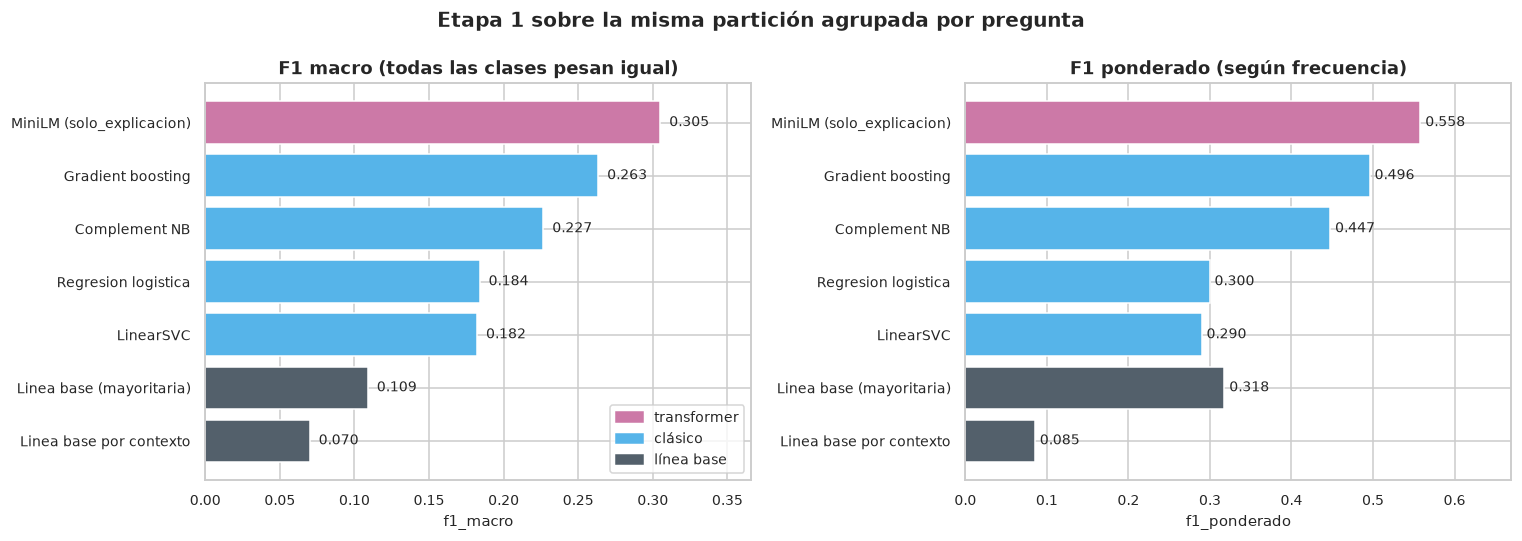

In [13]:
if hay_transformer:
    COLOR_FAMILIA = {
        "transformer": "#CC79A7",
        "clásico": COLOR_ALEATORIO,
        "línea base": COLOR_CONTEXTO,
    }

    fig, (izq, der) = plt.subplots(1, 2, figsize=(14, 5))
    d = misma_particion.sort_values("f1_macro")

    for ax, metrica, titulo in [
        (izq, "f1_macro", "F1 macro (todas las clases pesan igual)"),
        (der, "f1_ponderado", "F1 ponderado (según frecuencia)"),
    ]:
        colores = [COLOR_FAMILIA[f] for f in d["familia"]]
        ax.barh(d["modelo"], d[metrica], color=colores)
        for y_pos, v in enumerate(d[metrica]):
            ax.text(v + 0.006, y_pos, f"{v:.3f}", va="center", fontsize=9)
        ax.set_xlabel(metrica)
        ax.set_title(titulo)
        ax.set_xlim(0, d[metrica].max() * 1.2)

    manijas = [
        plt.Rectangle((0, 0), 1, 1, color=c) for c in COLOR_FAMILIA.values()
    ]
    izq.legend(manijas, COLOR_FAMILIA.keys(), loc="lower right", fontsize=9)
    fig.suptitle("Etapa 1 sobre la misma partición agrupada por pregunta",
                 fontsize=13, fontweight="bold")
    fig.tight_layout()
    print(guardar_figura(fig, "fig6_transformer_vs_clasicos"))
    plt.show()

### ¿Qué se observa?

Sobre la misma partición y con la misma métrica, el transformer destilado queda por encima de
los modelos clásicos. La ventaja es clara en F1 ponderado y más estrecha en F1 macro, lo que
indica que mejora sobre todo en las categorías frecuentes.

Conviene notar el resultado del experimento de entrada del cuaderno 04: añadir la respuesta
seleccionada al texto **empeoró** el desempeño del transformer, de 0.3050 a 0.2691 en F1 macro.
Es coherente con lo que mostró el análisis exploratorio. El contexto de la pregunta está tan
asociado con la etiqueta que, lejos de ayudar, invita al modelo a apoyarse en él y perjudica su
capacidad de generalizar a preguntas nuevas.

## 8. Tabla resumen para el informe

In [14]:
resumen = (
    metricas.pivot_table(
        index=["etapa", "modelo"], columns="esquema", values=["map@3", "f1_macro"]
    )
    .round(4)
)
resumen.columns = [f"{m}_{e}" for m, e in resumen.columns]
resumen = resumen.reset_index()
resumen.to_csv(DATA_TRANSFORMED / "resumen_informe.csv", index=False)
print("Guardado en data/transformed/resumen_informe.csv")
resumen

Guardado en data/transformed/resumen_informe.csv


,etapa,modelo,f1_macro_agrupado,f1_macro_aleatorio,map@3_agrupado,map@3_aleatorio
0,1. Category,Complement NB,0.2284,0.4209,0.5113,0.7319
1,1. Category,Gradient boosting,0.2491,0.4564,0.6096,0.7832
2,1. Category,Linea base (mayoritaria),0.0953,0.0958,0.4912,0.4924
3,1. Category,Linea base por contexto,0.0793,0.4095,0.2816,0.7601
4,1. Category,LinearSVC,0.2036,0.5483,0.4893,0.8131
5,1. Category,Regresion logistica,0.1994,0.5367,0.4891,0.8069
6,2. Misconception,Complement NB,0.0029,0.5995,0.0094,0.8715
7,2. Misconception,Gradient boosting,0.0017,0.5122,0.0075,0.7967
8,2. Misconception,Linea base (mayoritaria),0.0043,0.0076,0.0113,0.1944
9,2. Misconception,Linea base por contexto,0.0146,0.8257,0.1344,0.9593


In [15]:
print("Figuras generadas en reports/figures/:")
for p in sorted(FIGURES.glob("*.png")):
    print(f"  {p.name:38s} {p.stat().st_size / 1024:6.0f} KB")

Figuras generadas en reports/figures/:
  app1_explorar_datos.png                   340 KB
  app2_clasificar.png                       244 KB
  app3_rendimiento.png                      236 KB
  app4_comparacion_general.png              267 KB
  fig1_comparacion_modelos.png               82 KB
  fig2_brecha_validacion.png                 92 KB
  fig3_aporte_del_texto.png                  75 KB
  fig4_rendimiento_vs_costo.png              68 KB
  fig5_desbalance_y_cobertura.png           108 KB
  fig6_transformer_vs_clasicos.png          111 KB
